**Note for reviewers.** This notebook also contains analyses that are not reported in the paper: the player-swap columns of head-output patching and the matched-swap row of the attention-KL test. Those sections are kept only so the notebook runs as one unit, and their outputs should not be read as paper results.

**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB07 — Attention Heads: Where They Look and Whether They Are Needed

**Track B · Mechanistic interpretability of SEL-4L · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | For each of the 8 heads (4 layers × 2): where does it look from the target, does the acting player change where it looks, what does it write, and is it necessary for the arbitration specifically? |
| **Experiments** | E13 (descriptive), E14 (causal) |
| **Population** | P-player validation (estimation half for every E14 estimate); matched non-conflict controls; index-0 conflict rows; scored validation events for NLL |
| **Outputs** | `results/MB07_attention_relations.csv`, `results/MB07_attention_steering.csv`, `results/MB07_qk_layer0.csv`, `results/MB07_ov_readout.csv`, `results/MB07_ablation.parquet`, `results/MB07_ablation_summary.csv`, `results/MB07_pairs.csv`, `results/MB07_pseudo_heads.csv`, `results/MB07_summary.json`, `figures/MB07_*` |
| **Modules written** | `src/attention.py`, `src/circuits.py` (component ablation, path patching and faithfulness helpers; used again in MB08, MB10–MB12) |
| **Test data** | none |


In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
# Shared source is versioned with this notebook; do not overwrite repaired dependencies.
assert (MI_DIR / 'src/attention.py').exists(), "Missing dependency: src/attention.py"

> **⚠ REPAIR NOTE (2026-10-04) — SHARED SOURCE UPDATED — F01, F08.** The `%%writefile` cell below now writes the repaired `circuits.py`: `receiver_gradients` no longer detaches every receiver input (F01; the defective original is kept as `receiver_gradients_detached_legacy` for provenance only), and `random_circuit_space` / `enumerate_size_matched_circuits` report the number of distinct size-matched circuits (F08; `random_circuits` keeps its exact historical draws and now warns when draws repeat). Nothing MB07 computes uses these functions, so no MB07 result changes.

In [3]:
# Shared source is versioned with this notebook; do not overwrite repaired dependencies.
assert (MI_DIR / 'src/circuits.py').exists(), "Missing dependency: src/circuits.py"

In [4]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.attribution as attribution
import mi_src.attention as attention
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, attribution, attention, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [5]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(val_conflicts.groupby(["population", "half"]).size().unstack().to_string())

partners = pd.read_parquet(POP / "swap_partners.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
nll_table = circuits.scored_events(val_view, targets, bundle["match_ids"],
                                   limit=None if RUN_MODE == "full" else SETTINGS["max_events"] * 3)
HEADS = [f"L{l}H{h}" for l in range(N_LAYERS) for h in range(N_HEADS)]
print(f"P-player rows: {len(p_player):,} | matched controls: {len(controls):,} | index-0 rows: {len(index0):,} | "
      f"scored events for NLL: {len(nll_table):,} | heads: {HEADS}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 53 | primary seed 103 | identity variable: player
half        discovery  estimation
population                       
P-player         1215         529
index-0          4296        4651
P-player rows: 1,744 | matched controls: 252 | index-0 rows: 8,947 | scored events for NLL: 68,003 | heads: ['L0H0', 'L0H1', 'L1H0', 'L1H1', 'L2H0', 'L2H1', 'L3H0', 'L3H1']


## 1. Terms

| Term | Meaning here |
|---|---|
| **Attention head** | One of the two parallel units in each attention layer. From every position it takes a weighted average of information from the same and earlier positions. |
| **Query, key, value** | What a position is looking for (query), what each earlier position offers to be found by (key), and what that position passes on if it is looked at (value). |
| **Attention pattern** | The weights (summing to 1) with which the target position reads each allowed position. |
| **QK circuit** | The part of a head that decides *where* it looks (query · key). |
| **OV circuit** | The part of a head that decides *what* it writes once it has looked (value, then output matrix W_O). |
| **Ablation** | Removing a component's contribution to test whether it is needed. |
| **Mean ablation** | Replacing a component's output by its average over 2,000 reference validation windows at the same position (MB02). Zero is not used because the model never produces a zero output. |
| **Resample ablation** | Replacing it by its value at the same position in a random other validation window; averaged over `n_draws` draws. |
| **Specificity** | Whether ablating a head changes Δ on conflict events more than on matched non-conflict events. |

**A striking attention pattern is not evidence that a head matters.** Sections 2–5 describe; only Sections 6–8 test necessity.

## 2. E13 Step 1 — Where each head looks from the target

**Research question.** Which earlier events does each head read when SEL-4L scores a conflict event?

**Measure.** For the target query, the attention share on six relations (the target itself, the previous event, earlier events of the same player, earlier events of the same team, earlier events that follow a change of acting team, position 0) against the share expected under uniform attention over the allowed positions (1 / (t + 1) per position). The per-event difference *actual share − uniform share* is averaged with a match-bootstrap interval.

**Hypothesis (H3, identity-conditioned reading of context).** A head that reads earlier events of the same player more than uniform attention would is a candidate for reading the player's own history; this section cannot say whether that matters.

In [6]:
relation_rows, profiles = [], []
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_player, BATCH):
        chunk = p_player.iloc[part]
        _, cache = hooks.forward(MODEL, inputs, capture=[f"attn_pattern_{l}" for l in range(N_LAYERS)])
        masks = attention.relation_masks(inputs, positions)
        for layer in range(N_LAYERS):
            rows = attention.query_rows(cache[f"attn_pattern_{layer}"], positions)
            profiles.append((layer, attention.offset_profile(rows, positions, rows.shape[-1]).cpu().numpy()))
            for relation, (attended, uniform) in attention.relation_shares(rows, masks, positions).items():
                for head in range(N_HEADS):
                    relation_rows.append(pd.DataFrame({"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                                                       "head": f"L{layer}H{head}", "relation": relation,
                                                       "attended": attended[:, head].cpu().numpy(), "uniform": uniform.cpu().numpy()}))
relations = pd.concat(relation_rows, ignore_index=True)
relations["excess"] = relations["attended"] - relations["uniform"]
relation_summary = []
for (head, relation), group in relations.groupby(["head", "relation"], sort=False):
    summary = mi_metrics.summarise(group["excess"], group["match_id"], N_BOOT)
    relation_summary.append({"head": head, "relation": relation, "mean attention share": group["attended"].mean(),
                             "mean uniform share": group["uniform"].mean(), "mean excess": summary["mean"],
                             "CI low": summary["ci_low"], "CI high": summary["ci_high"], "n": summary["n"]})
relation_summary = pd.DataFrame(relation_summary)
relation_summary.to_csv(OUT / "results" / "MB07_attention_relations.csv", index=False)
print(relation_summary.pivot(index="head", columns="relation", values="mean excess").reindex(HEADS).round(3).to_string())

relation  after a team change (earlier)  first position  previous event  same player (earlier)  same team (earlier)   self
head                                                                                                                      
L0H0                              0.028          -0.066           0.183                  0.019               -0.120  0.138
L0H1                              0.056          -0.067           0.130                  0.030               -0.076  0.224
L1H0                             -0.024          -0.035           0.028                  0.000               -0.072  0.183
L1H1                              0.070          -0.032           0.056                  0.039               -0.008  0.166
L2H0                              0.038          -0.024           0.012                  0.021               -0.023  0.159
L2H1                             -0.029          -0.030          -0.001                 -0.019               -0.102  0.258
L3H0            

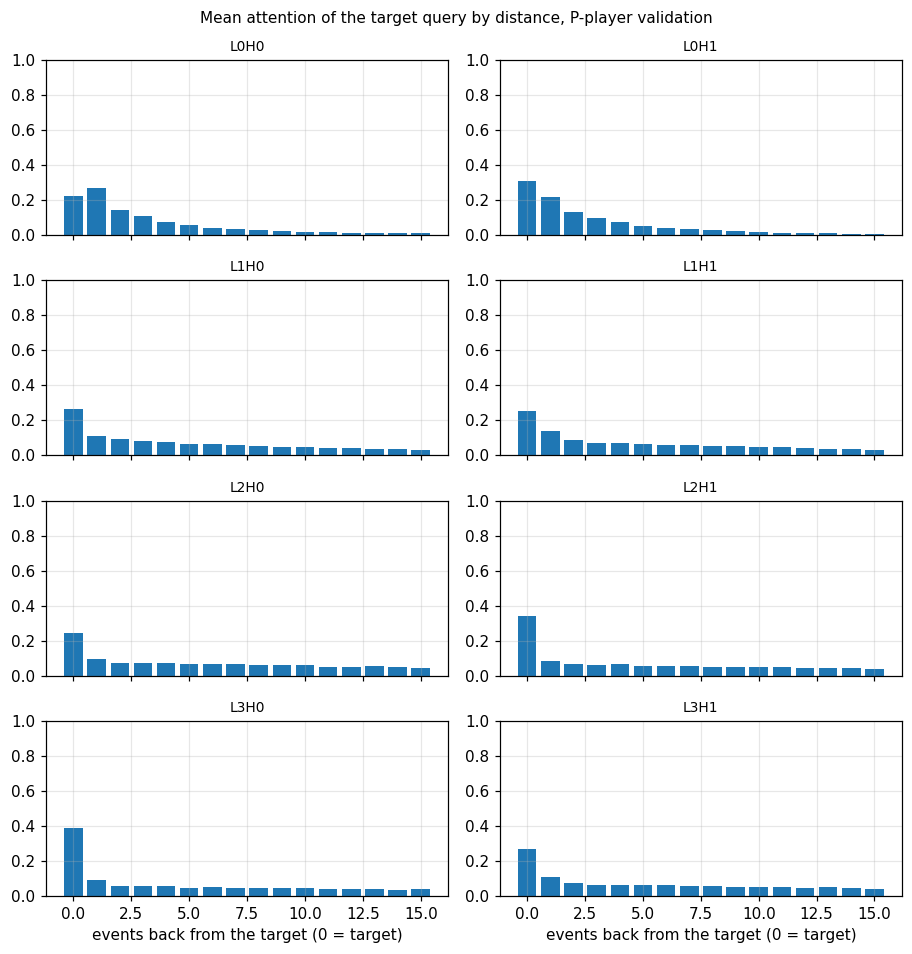

In [7]:
fig, axes = plt.subplots(N_LAYERS, N_HEADS, figsize=(4.2 * N_HEADS, 2.2 * N_LAYERS), sharex=True)
axes = np.atleast_2d(axes)
for layer in range(N_LAYERS):
    stacked = np.concatenate([profile for l, profile in profiles if l == layer], axis=0)
    for head in range(N_HEADS):
        mean_profile = np.nanmean(stacked[:, head, :], axis=0)
        axis = axes[layer, head]
        axis.bar(np.arange(len(mean_profile)), mean_profile, color="tab:blue")
        axis.set_title(f"L{layer}H{head}", fontsize=9); axis.set_ylim(0, 1)
        if layer == N_LAYERS - 1:
            axis.set_xlabel("events back from the target (0 = target)")
plt.suptitle("Mean attention of the target query by distance, P-player validation", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB07_attention_profiles.png", bbox_inches="tight"); plt.show()

**How to read.** The table gives, per head and relation, how much more (positive) or less (negative) attention the target gives that relation than uniform attention would. The bar charts show the average attention by distance. Both describe the pattern only.

## 3. E13 Step 2 — Does the acting player steer attention?

**Research question.** Does changing only the player at the target change where each head looks from the target?

**Measure.** KL(pattern before ‖ pattern after) of the target query's attention row, per head, under I1 (player → 0), I2 (matched partner) and I4 (norm-matched random vector, `n_draws` draws averaged). Layer-0 queries see the player directly; later layers see it through the residual stream.

**Control.** I4 gives the change caused by an arbitrary vector of the same size. **Statistic:** paired per-event differences KL(I1) − KL(I4) and KL(I2) − KL(I4); match-bootstrap interval and one-sided p-value; Benjamini–Hochberg over the 8 heads within each contrast. Estimation half.

In [8]:
steer_rows = []
generator = torch.Generator().manual_seed(0)
pattern_sites = [f"attn_pattern_{l}" for l in range(N_LAYERS)]
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_player, BATCH):
        chunk = p_player.iloc[part]
        _, base = hooks.forward(MODEL, inputs, capture=pattern_sites)
        runs = {"I1": hooks.forward(MODEL, interventions.remove_feature(inputs, "player", positions), capture=pattern_sites)[1]}
        own = chunk["player"].to_numpy()
        partner = np.array([partner_of.get(p, -1) for p in own])
        swapped = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(partner > 0, partner, own), device=DEVICE))
        runs["I2"] = hooks.forward(MODEL, swapped, capture=pattern_sites)[1]
        vector_runs = [hooks.forward(MODEL, inputs, replace={"factor_player": interventions.norm_matched_vector(None, positions, generator)},
                                     capture=pattern_sites)[1] for _ in range(SETTINGS["n_draws"])]
        for layer in range(N_LAYERS):
            site = f"attn_pattern_{layer}"
            before = attention.query_rows(base[site], positions)
            kl = {code: attention.row_kl(before, attention.query_rows(cache[site], positions)) for code, cache in runs.items()}
            kl["I4"] = torch.stack([attention.row_kl(before, attention.query_rows(cache[site], positions)) for cache in vector_runs]).mean(0)
            for head in range(N_HEADS):
                steer_rows.append(pd.DataFrame({"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                                                "half": chunk["half"].to_numpy(), "head": f"L{layer}H{head}",
                                                "KL_I1": kl["I1"][:, head].cpu().numpy(),
                                                "KL_I2": np.where(partner > 0, kl["I2"][:, head].cpu().numpy(), np.nan),
                                                "KL_I4": kl["I4"][:, head].cpu().numpy()}))
steering = pd.concat(steer_rows, ignore_index=True)
steer_summary = []
estimation_steering = steering[steering.half == "estimation"]
for contrast in ["I1", "I2"]:
    block = []
    for head in HEADS:
        frame = estimation_steering[(estimation_steering["head"] == head)].dropna(subset=[f"KL_{contrast}"])
        difference = frame[f"KL_{contrast}"] - frame["KL_I4"]
        summary = mi_metrics.summarise(difference, frame["match_id"], N_BOOT)
        block.append({"contrast": contrast, "head": head, "mean KL": frame[f"KL_{contrast}"].mean(), "mean KL (I4)": frame["KL_I4"].mean(),
                      "mean difference": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                      "p (greater)": mi_metrics.bootstrap_pvalue(difference, frame["match_id"], N_BOOT, alternative="greater"),
                      "n": summary["n"]})
    block = pd.DataFrame(block)
    block["q-value (BH over heads)"] = mi_metrics.benjamini_hochberg(block["p (greater)"].to_numpy(), 0.05)[1]
    steer_summary.append(block)
steer_summary = pd.concat(steer_summary, ignore_index=True)
steer_summary.to_csv(OUT / "results" / "MB07_attention_steering.csv", index=False)
print(steer_summary.round(4).to_string(index=False))

contrast head  mean KL  mean KL (I4)  mean difference  CI low  CI high  p (greater)   n  q-value (BH over heads)
      I1 L0H0   0.0275        0.0422          -0.0147 -0.0168  -0.0132       1.0000 529                   1.0000
      I1 L0H1   0.0246        0.0388          -0.0142 -0.0161  -0.0123       1.0000 529                   1.0000
      I1 L1H0   0.0214        0.0353          -0.0139 -0.0150  -0.0123       1.0000 529                   1.0000
      I1 L1H1   0.0153        0.0293          -0.0140 -0.0155  -0.0123       1.0000 529                   1.0000
      I1 L2H0   0.0208        0.0400          -0.0192 -0.0215  -0.0174       1.0000 529                   1.0000
      I1 L2H1   0.0312        0.0557          -0.0245 -0.0293  -0.0202       1.0000 529                   1.0000
      I1 L3H0   0.0439        0.0726          -0.0287 -0.0344  -0.0221       1.0000 529                   1.0000
      I1 L3H1   0.0242        0.0466          -0.0224 -0.0271  -0.0166       1.0000 529         

## 4. E13 Step 3 — Layer-0 QK readout

**Question.** Which relations does the player vector raise or lower in the attention scores of the layer-0 heads, whose queries read the embedding directly?

**Measure.** The change in the pre-softmax score from the target query to each key when the player at the target is removed (clean − I1), averaged over the keys of each relation. (The key at the target itself also changes, because the target reads its own position.) Later layers are described only through Section 3, because their queries mix many inputs.

In [9]:
qk_rows = []
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_player, BATCH):
        chunk = p_player.iloc[part]
        _, clean = hooks.forward(MODEL, inputs, capture=["attn_scores_0"])
        _, removed = hooks.forward(MODEL, interventions.remove_feature(inputs, "player", positions), capture=["attn_scores_0"])
        rows = torch.arange(len(positions), device=DEVICE)
        change = clean["attn_scores_0"][rows, :, positions, :] - removed["attn_scores_0"][rows, :, positions, :]
        masks = attention.relation_masks(inputs, positions)
        for relation, mask in masks.items():
            count = mask.float().sum(-1)
            safe = torch.where(mask.unsqueeze(1), change, torch.zeros_like(change))
            mean_change = safe.sum(-1) / count.clamp(min=1).unsqueeze(1)
            for head in range(N_HEADS):
                values = mean_change[:, head].cpu().numpy()
                qk_rows.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "head": f"L0H{head}", "relation": relation,
                                             "score_change": np.where(count.cpu().numpy() > 0, values, np.nan)}))
qk = pd.concat(qk_rows, ignore_index=True).dropna()
qk_summary = []
for (head, relation), group in qk.groupby(["head", "relation"], sort=False):
    summary = mi_metrics.summarise(group["score_change"], group["match_id"], N_BOOT)
    qk_summary.append({"head": head, "relation": relation, "mean score change": summary["mean"], "CI low": summary["ci_low"],
                       "CI high": summary["ci_high"], "n": summary["n"]})
qk_summary = pd.DataFrame(qk_summary)
qk_summary.to_csv(OUT / "results" / "MB07_qk_layer0.csv", index=False)
print(qk_summary.round(4).to_string(index=False))

head                      relation  mean score change  CI low  CI high    n
L0H0                          self            -0.0351 -0.1091   0.0369 1744
L0H1                          self            -0.1000 -0.1746  -0.0326 1744
L0H0                previous event            -0.0765 -0.0988  -0.0559 1744
L0H1                previous event            -0.0572 -0.0719  -0.0423 1744
L0H0         same player (earlier)             0.0075 -0.0126   0.0253  894
L0H1         same player (earlier)            -0.0126 -0.0269   0.0016  894
L0H0           same team (earlier)             0.0392  0.0188   0.0575 1558
L0H1           same team (earlier)             0.0352  0.0158   0.0539 1558
L0H0 after a team change (earlier)             0.0050 -0.0156   0.0238 1592
L0H1 after a team change (earlier)            -0.0009 -0.0123   0.0119 1592
L0H0                first position             0.1205  0.0814   0.1578 1744
L0H1                first position             0.1098  0.0754   0.1463 1744


## 5. E13 Step 4 — OV readout: what each head writes towards a_ctx or a_id

**Measure.** Each head's direct contribution to Δ at the target through the frozen final LayerNorm (the decomposition of `attribution.py`, checked in MB02 test 6 and used in full in MB09), on the recorded event and under I1. Positive = the head writes towards the context-favoured action a_ctx; negative = towards the identity-favoured action a_id. The change under I1 shows how much of that write depends on the player. This is a direct-write description (level 1), not a necessity test.

In [10]:
ov_rows = []
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, p_player, BATCH):
        chunk = p_player.iloc[part]
        _, clean = hooks.forward(MODEL, inputs, capture="all")
        _, removed = hooks.forward(MODEL, interventions.remove_feature(inputs, "player", positions), capture="all")
        clean_terms, _ = attribution.decompose(MODEL, clean, positions, a_ctx, a_id)
        removed_terms, _ = attribution.decompose(MODEL, removed, positions, a_ctx, a_id)
        for layer in range(N_LAYERS):
            for head in range(N_HEADS):
                name = f"L{layer} head {head}"
                ov_rows.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "half": chunk["half"].to_numpy(),
                                             "head": f"L{layer}H{head}", "direct_write": clean_terms[name],
                                             "change_under_I1": clean_terms[name] - removed_terms[name]}))
ov = pd.concat(ov_rows, ignore_index=True)
ov_summary = []
for head, group in ov.groupby("head", sort=False):
    write = mi_metrics.summarise(group["direct_write"], group["match_id"], N_BOOT)
    change = mi_metrics.summarise(group["change_under_I1"], group["match_id"], N_BOOT)
    ov_summary.append({"head": head, "mean direct write": write["mean"], "CI low": write["ci_low"], "CI high": write["ci_high"],
                       "mean change under I1": change["mean"], "I1 CI low": change["ci_low"], "I1 CI high": change["ci_high"]})
ov_summary = pd.DataFrame(ov_summary)
ov_summary.to_csv(OUT / "results" / "MB07_ov_readout.csv", index=False)
print(ov_summary.round(4).to_string(index=False))

head  mean direct write  CI low  CI high  mean change under I1  I1 CI low  I1 CI high
L0H0             0.0086  0.0041   0.0126               -0.0001    -0.0008      0.0006
L0H1             0.0236  0.0177   0.0286               -0.0023    -0.0032     -0.0014
L1H0             0.0238  0.0197   0.0285               -0.0026    -0.0040     -0.0012
L1H1            -0.0040 -0.0142   0.0061                0.0007    -0.0002      0.0017
L2H0            -0.0168 -0.0234  -0.0099                0.0009    -0.0002      0.0022
L2H1            -0.0170 -0.0222  -0.0124               -0.0024    -0.0045     -0.0007
L3H0             0.0293  0.0141   0.0440               -0.0024    -0.0046     -0.0002
L3H1             0.0062 -0.0094   0.0223               -0.0017    -0.0053      0.0016


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 6. E14 Step 5 — Head patching from MB06

The MB06 sweep already patched each head's output at the target. Its pooled recovery per head is shown here next to the ablation results (identity contrasts at the target; for the context contrast, the position with the largest estimation-half recovery).

In [11]:
site_summary = pd.read_csv(OUT / "results" / "MB06_site_summary.csv")
head_sites = site_summary[site_summary["site"].str.contains("head")].copy()
head_sites["head"] = head_sites["site"].str.replace(r"L(\d) head (\d)", r"L\1H\2", regex=True)
identity_part = head_sites[(head_sites.contrast != "context") & (head_sites.offset == 0)]
patch_table = identity_part.pivot_table(index="head", columns=["contrast", "direction", "half"], values="pooled recovery")
context_part = head_sites[(head_sites.contrast == "context") & (head_sites.half == "estimation")]
if len(context_part):
    best = context_part.loc[context_part.groupby(["head", "direction"])["pooled recovery"].apply(lambda s: s.abs().idxmax())]
    context_table = best.pivot(index="head", columns="direction", values=["pooled recovery", "offset"])
    context_table.columns = [f"context {a} ({b}, estimation)" for a, b in context_table.columns]
    print(context_table.reindex(HEADS).round(3).to_string()); print()
print(patch_table.reindex(HEADS).round(3).to_string())

      context pooled recovery (denoise, estimation)  context pooled recovery (noise, estimation)  context offset (denoise, estimation)  context offset (noise, estimation)
head                                                                                                                                                                      
L0H0                                          0.001                                        0.016                                   0.0                                 0.0
L0H1                                         -0.004                                        0.012                                   0.0                                 0.0
L1H0                                          0.002                                        0.016                                   0.0                                 0.0
L1H1                                          0.010                                       -0.001                                   0.0           

## 7. E14 Step 6 — Ablation of single heads and head pairs

**Research question.** Is a head *necessary* for the arbitration on conflict events, and more so than for comparable non-conflict events?

**Hypothesis.** Some heads are necessary for Δ on P-player conflicts (mean change ≠ 0) and specifically so (|change| on conflicts > |change| on matched controls).

**Competing outcome.** Every head's ablation moves Δ equally on conflicts and controls (general damage), or no head's ablation moves Δ (redundancy).

**Design.** Each head is mean-ablated and resample-ablated (`n_draws` draws), (a) at the target position only and (b) at every position. All 28 head pairs are mean-ablated at every position. Measured on each event: the change in Δ (ablated − intact) on P-player conflicts, on their matched controls, and on index-0 conflicts; and the change in the NLL of the true action on scored validation events.

**Statistics (estimation half).** Mean change with match-bootstrap interval and two-sided p-value. **Specificity:** per conflict–control pair, |change on the conflict| − |change on its control|; one-sided p-value (greater). Benjamini–Hochberg at q = 0.05 over the 36 units (8 heads + 28 pairs) per measure, mean ablation at every position; over the 8 heads for the other conditions.

In [12]:
def unit_name(components):
    return "+".join(components)

# On CPU, use larger batches to improve throughput. These are still the same rows,
# interventions, and resampling draws. Save completed heads so an interrupted run resumes safely.
import base64, hashlib, json, nbformat
ABLATION_BATCH = min(512, int(BATCH * 2))
tables = {"P-player": p_player, "matched controls": controls, "index-0": index0}
panel = circuits.AblationPanel(MODEL, bundle, val_view, tables, nll_table, ABLATION_BATCH)
start = time.time()
records = []
resample_generator = torch.Generator().manual_seed(0)
partial_dir = OUT / "results" / "MB07_head_checkpoints"
partial_dir.mkdir(parents=True, exist_ok=True)
other_code = [cell.source for cell in nbformat.read(next((MI_DIR / "notebooks").glob("MB07_*.ipynb")), as_version=4).cells
              if cell.cell_type == "code" and cell.id != "408d2c31"]
contract = {
    "algorithm_version": "primary-head-ablation-resume-v1",
    "other_notebook_code_sha256": hashlib.sha256(json.dumps(other_code, sort_keys=True).encode()).hexdigest(),
    "analysis_id": mi_setup.load_json(OUT / "config" / "analysis_plan.json")["analysis_id"],
    "checkpoint_sha256": fingerprint.file_sha256(run_dir(PRIMARY_SEED) / "best.pt"),
    "mi_config_sha256": fingerprint.file_sha256(OUT / "config" / "mi_config.json"),
    "circuits_source_sha256": fingerprint.file_sha256(MI_DIR / "src" / "circuits.py"),
    "batch_windows": ABLATION_BATCH, "n_draws": int(SETTINGS["n_draws"]),
    "nll_rows": len(nll_table), "heads": HEADS,
}
completed = []
for head in HEADS:
    data_path = partial_dir / f"{head}.parquet"
    metadata_path = partial_dir / f"{head}.json"
    if not data_path.exists() and not metadata_path.exists():
        break
    if not data_path.exists() or not metadata_path.exists():
        raise RuntimeError(f"BLOCKED: incomplete checkpoint for {head}")
    metadata = mi_setup.load_json(metadata_path)
    if metadata["head"] != head or metadata["contract"] != contract:
        raise RuntimeError(f"BLOCKED: checkpoint contract mismatch for {head}; refusing to mix analyses")
    records.append(pd.read_parquet(data_path))
    completed.append(head)
    resample_generator.set_state(torch.as_tensor(list(base64.b64decode(metadata["rng_state_b64"])), dtype=torch.uint8))
print(f"Resuming after {len(completed)} of {len(HEADS)} heads; batch={ABLATION_BATCH}", flush=True)

for head in HEADS[len(completed):]:
    head_start = time.time()
    record_start = len(records)
    for scope, at_target in [("target", True), ("all positions", False)]:
        changes, nll_change = panel.changes(lambda: circuits.mean_ablation([head], MEANS, at_target))
        records.append(panel.rows(head, "mean", scope, changes, nll_change))
        changes, nll_change = panel.changes(lambda: circuits.resample_ablation(MODEL, bundle, val_view, REFERENCE_WINDOWS, [head],
                                                                               at_target, resample_generator), SETTINGS["n_draws"])
        records.append(panel.rows(head, "resample", scope, changes, nll_change))
    part = pd.concat(records[record_start:], ignore_index=True)
    temp_path = partial_dir / f"{head}.tmp.parquet"
    part.to_parquet(temp_path, index=False)
    temp_path.replace(partial_dir / f"{head}.parquet")
    metadata = {"head": head, "contract": contract,
                "rng_state_b64": base64.b64encode(bytes(resample_generator.get_state().tolist())).decode("ascii"),
                "completed_at": fingerprint.now()}
    temp_meta = partial_dir / f"{head}.tmp.json"
    temp_meta.write_text(json.dumps(metadata, indent=2))
    temp_meta.replace(partial_dir / f"{head}.json")
    print(f"Completed {head}: {len(part):,} rows in {time.time()-head_start:.0f}s; elapsed {time.time()-start:.0f}s", flush=True)

pairs = [(HEADS[i], HEADS[j]) for i in range(len(HEADS)) for j in range(i + 1, len(HEADS))]
for pair in pairs:
    changes, nll_change = panel.changes(lambda: circuits.mean_ablation(list(pair), MEANS, False))
    records.append(panel.rows(unit_name(pair), "mean", "all positions", changes, nll_change))
ablation = pd.concat(records, ignore_index=True)
ablation.to_parquet(OUT / "results" / "MB07_ablation.parquet", index=False)
print(f"{len(pairs)} pairs done; {len(ablation):,} rows stored; {time.time() - start:.0f} s", flush=True)


Resuming after 8 of 8 heads; batch=512


28 pairs done; 4,736,760 rows stored; 51 s


In [13]:
unit_summary = circuits.summarise_ablation(ablation, controls, N_BOOT)
unit_summary.to_csv(OUT / "results" / "MB07_ablation_summary.csv", index=False)
show = ["unit", "method", "scope", "P-player: mean change", "P-player: CI low", "P-player: CI high", "P-player: q",
        "matched controls: mean change", "index-0: mean change", "NLL (scored events): mean change",
        "specificity: mean", "specificity: CI low", "specificity: q"]
singles = unit_summary[unit_summary["unit"].isin(HEADS)]
print("Single heads (estimation half; q-values: BH within each method x scope; mean/all-positions over 36 units):")
print(singles[[c for c in show if c in singles]].round(4).to_string(index=False))

Single heads (estimation half; q-values: BH within each method x scope; mean/all-positions over 36 units):
unit   method         scope  P-player: mean change  P-player: CI low  P-player: CI high  P-player: q  matched controls: mean change  index-0: mean change  NLL (scored events): mean change  specificity: mean  specificity: CI low  specificity: q
L0H0     mean        target                -0.0305           -0.0795             0.0190       0.3198                         0.0258               -0.0179                            0.0165            -0.1066              -0.2382          0.9935
L0H0 resample        target                -0.1353           -0.1943            -0.0694       0.0016                        -0.0779               -0.1268                            0.0350            -0.1878              -0.3253          1.0000
L0H0     mean all positions                -0.0231           -0.0735             0.0278       0.4016                         0.0442               -0.0168        

In [14]:
single_all = ablation[(ablation.method == "mean") & (ablation.scope == "all positions") & (ablation.population == "P-player")
                      & (ablation.half == "estimation")]
by_unit = {unit: group.set_index("event_row")["change"] for unit, group in single_all.groupby("unit")}
pair_rows = []
for a, b in pairs:
    pair_change = by_unit[unit_name((a, b))]
    interaction = pair_change - (by_unit[a] + by_unit[b]).reindex(pair_change.index)
    match_of = p_player.set_index("event_row").loc[pair_change.index, "match_id"]
    summary = mi_metrics.summarise(interaction.to_numpy(), match_of.to_numpy(), N_BOOT)
    pair_rows.append({"head a": a, "head b": b, "mean pair change": pair_change.mean(),
                      "mean sum of singles": (by_unit[a] + by_unit[b]).reindex(pair_change.index).mean(),
                      "mean interaction": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
pair_table = pd.DataFrame(pair_rows)
pair_table.to_csv(OUT / "results" / "MB07_pairs.csv", index=False)
print("Pair interaction = pair effect - (effect of a + effect of b); P-player, estimation half, mean ablation at every position")
print(pair_table.round(4).to_string(index=False))

Pair interaction = pair effect - (effect of a + effect of b); P-player, estimation half, mean ablation at every position
head a head b  mean pair change  mean sum of singles  mean interaction  CI low  CI high
  L0H0   L0H1           -0.1662              -0.1242           -0.0420 -0.0539  -0.0311
  L0H0   L1H0           -0.0625              -0.0504           -0.0121 -0.0300   0.0018
  L0H0   L1H1            0.1051               0.1164           -0.0113 -0.0189  -0.0017
  L0H0   L2H0            0.0249               0.0137            0.0111 -0.0013   0.0238
  L0H0   L2H1           -0.0225              -0.0206           -0.0019 -0.0117   0.0083
  L0H0   L3H0           -0.2205              -0.2078           -0.0127 -0.0210  -0.0052
  L0H0   L3H1           -0.1995              -0.2147            0.0152 -0.0003   0.0324
  L0H1   L1H0           -0.1567              -0.1285           -0.0283 -0.0411  -0.0141
  L0H1   L1H1            0.0723               0.0384            0.0339  0.0144   0.0468

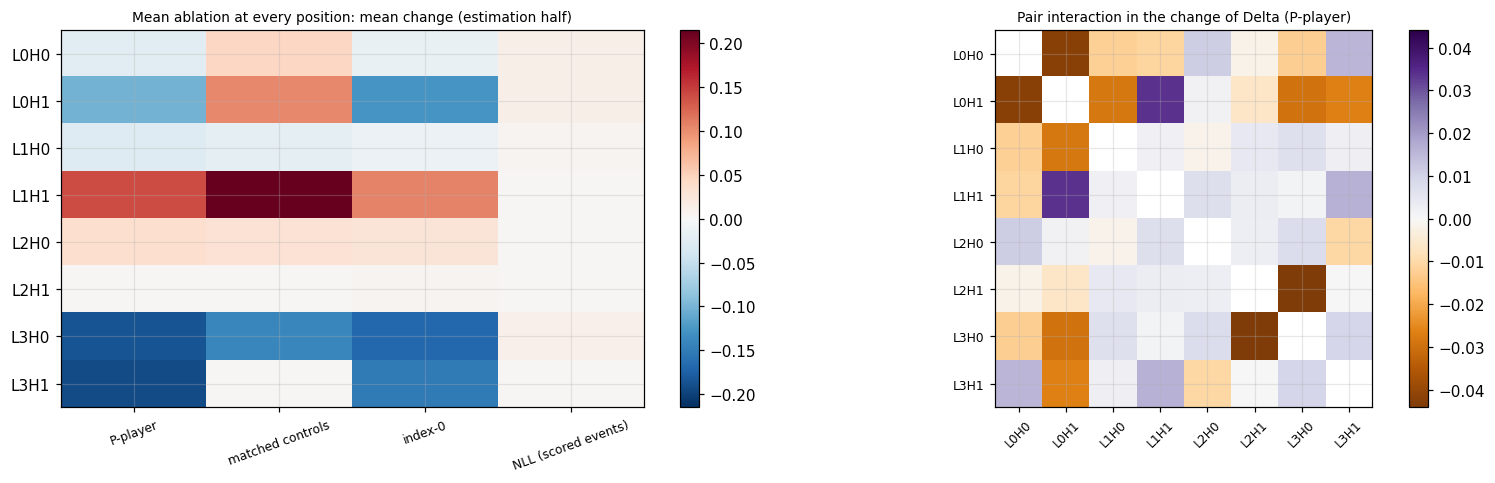

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
heat = singles[(singles.method == "mean") & (singles.scope == "all positions")].set_index("unit").reindex(HEADS)
columns = ["P-player: mean change", "matched controls: mean change", "index-0: mean change", "NLL (scored events): mean change"]
values = heat[[c for c in columns if c in heat]].to_numpy()
limit = np.nanmax(np.abs(values)) if np.isfinite(values).any() else 1
image = axes[0].imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axes[0].set_yticks(range(len(HEADS))); axes[0].set_yticklabels(HEADS)
axes[0].set_xticks(range(values.shape[1])); axes[0].set_xticklabels([c.split(":")[0] for c in columns if c in heat], rotation=20, fontsize=8)
axes[0].set_title("Mean ablation at every position: mean change (estimation half)", fontsize=9)
plt.colorbar(image, ax=axes[0])
matrix = pd.DataFrame(np.nan, index=HEADS, columns=HEADS)
for _, row in pair_table.iterrows():
    matrix.loc[row["head a"], row["head b"]] = row["mean interaction"]
    matrix.loc[row["head b"], row["head a"]] = row["mean interaction"]
limit = np.nanmax(np.abs(matrix.to_numpy())) if np.isfinite(matrix.to_numpy()).any() else 1
image = axes[1].imshow(matrix.to_numpy(), cmap="PuOr", vmin=-limit, vmax=limit)
axes[1].set_xticks(range(len(HEADS))); axes[1].set_xticklabels(HEADS, rotation=45, fontsize=8)
axes[1].set_yticks(range(len(HEADS))); axes[1].set_yticklabels(HEADS, fontsize=8)
axes[1].set_title("Pair interaction in the change of Delta (P-player)", fontsize=9)
plt.colorbar(image, ax=axes[1])
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB07_ablation.png", bbox_inches="tight"); plt.show()

Signed non-additivity is pair change minus the sum of single changes. Its sign depends on the direction of Δ and does not alone identify overlap, compensation or redundancy.


## 8. Control — random "pseudo-heads"

**Why.** A head's ablation effect must be compared with what removing an arbitrary part of the same layer's attention output of the same size would do.

**Design.** For each layer, `n_random_circuits` random 64-dimensional subspaces (the size of one head's output) of the 128-dimensional attention output are drawn; in each, the attention output's component in that subspace is mean-ablated at every position (x ← x − P Pᵀ (x − x̄), with P an orthonormal 128 × 64 basis and x̄ the reference mean). The mean |change in Δ| on P-player (estimation half) of each real head is placed as a percentile in its layer's pseudo-head distribution.

In [16]:
estimation_pplayer = p_player[p_player.half == "estimation"].reset_index(drop=True)
estimation_intact = circuits.deltas(MODEL, bundle, val_view, estimation_pplayer, BATCH)
rng = np.random.default_rng(0)
pseudo_rows = []
for layer in range(N_LAYERS):
    mean_out = MEANS[f"attn_out_{layer}"]
    for draw in range(SETTINGS["n_random_circuits"]):
        basis, _ = np.linalg.qr(rng.standard_normal((mean_out.shape[-1], MODEL.blocks[layer].attention.d_head)))
        basis = torch.as_tensor(basis, dtype=mean_out.dtype, device=DEVICE)
        def builder(inputs, positions, basis=basis, mean_out=mean_out, layer=layer):
            return {f"attn_out_{layer}": lambda value: value - ((value - mean_out.unsqueeze(0)) @ basis) @ basis.T}
        change = circuits.deltas(MODEL, bundle, val_view, estimation_pplayer, BATCH, builder) - estimation_intact
        pseudo_rows.append({"layer": layer, "draw": draw, "mean abs change": float(np.abs(change).mean())})
pseudo = pd.DataFrame(pseudo_rows)
pseudo.to_csv(OUT / "results" / "MB07_pseudo_heads.csv", index=False)
real = ablation[(ablation.method == "mean") & (ablation.scope == "all positions") & (ablation.population == "P-player")
                & (ablation.half == "estimation") & ablation.unit.isin(HEADS)]
percentile_rows = []
for head, group in real.groupby("unit"):
    layer = int(head[1])
    distribution = pseudo.loc[pseudo.layer == layer, "mean abs change"].to_numpy()
    value = float(np.abs(group["change"]).mean())
    percentile_rows.append({"head": head, "mean |change| (head)": value, "pseudo-head median": float(np.median(distribution)),
                            "pseudo-head 95th percentile": float(np.percentile(distribution, 95)),
                            "percentile of head in pseudo-head distribution": float((distribution < value).mean() * 100)})
percentiles = pd.DataFrame(percentile_rows).set_index("head").reindex(HEADS)
print(percentiles.round(4).to_string())

      mean |change| (head)  pseudo-head median  pseudo-head 95th percentile  percentile of head in pseudo-head distribution
head                                                                                                                       
L0H0                0.3324              0.3475                       0.4266                                            33.0
L0H1                0.2984              0.3475                       0.4266                                             5.0
L1H0                0.2172              0.1828                       0.2063                                            98.0
L1H1                0.2137              0.1828                       0.2063                                            97.0
L2H0                0.1636              0.1257                       0.1428                                           100.0
L2H1                0.1403              0.1257                       0.1428                                            91.0
L3H0    

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

In [17]:
summary = {"relations": relation_summary.to_dict(orient="records"), "steering": steer_summary.to_dict(orient="records"),
           "ov": ov_summary.to_dict(orient="records"), "single_heads": singles.to_dict(orient="records"),
           "pseudo_head_percentiles": percentiles.reset_index().to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB07_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB07_summary.json": OUT / "results" / "MB07_summary.json",
                                    "results/MB07_ablation.parquet": OUT / "results" / "MB07_ablation.parquet"})
fingerprint.register(REGISTRY, {"notebook": "MB07", "experiment": "E13-E14 attention heads", "seed": PRIMARY_SEED,
                                "n_units": int(unit_summary["unit"].nunique()), "run_mode": RUN_MODE})
print("saved")

saved
